## Import

In [1]:
import json, os, time, pickle, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, average_precision_score, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Setup

In [2]:
SEED = 42
N_TRIALS = 30
INNER_K = 3
K = 5                    # repeat 1 of the shared folds
FRACS = [0.25, 0.5, 0.75, 1.0]   # share of each outer training fold that is kept
np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("weights_V7_1", exist_ok=True); os.makedirs("media", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()  # 2213 rows (target must not be imputed)
print("cleaned:", df.shape, "| Income max:", f"{df['Income'].max():,.0f}", "| median:", f"{df['Income'].median():,.0f}")
REG_FEATURES = ["NumCatalogPurchases","MntMeatProducts","MntWines","NumWebVisitsMonth","MntSweetProducts",
    "MntFruits","NumWebPurchases","MntGoldProds","NumStorePurchases","MntFishProducts","Kidhome","Age","NumDealsPurchases"]
X_full = df[REG_FEATURES].values; y_raw = df["Income"].values.astype(float)
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

cleaned: (2212, 28) | Income max: 162,397 | median: 51,371
features: 13 dims (all numeric)


In [4]:
# Feature interaction hand-off (Feature Interaction section of regression.ipynb):
# Teenhome interacts with most spend features but is not in the 13-feature model set.
EXTRA = ["Teenhome"]
COLS_ALL = REG_FEATURES + EXTRA
X_all = df[COLS_ALL].values.astype(float)

def top_pairs(csv_path, cols, k, must_include=None, exclude=None):
    """Top-k significant (q < 0.05) pairs by effect size where both features are in `cols`."""
    t = pd.read_csv(csv_path)
    t = t[(t.q < 0.05) & t.A.isin(cols) & t.B.isin(cols)]
    if must_include is not None:
        t = t[t.A.eq(must_include) | t.B.eq(must_include)]
    if exclude is not None:
        t = t[~(t.A.eq(exclude) | t.B.eq(exclude))]
    t = t.sort_values("effect", ascending=False)
    return list(zip(t.A.head(k), t.B.head(k)))

PAIRS_13 = top_pairs("results/interaction_reg.csv", REG_FEATURES, 4)
PAIRS_T = top_pairs("results/interaction_reg.csv", COLS_ALL, 5, must_include="Teenhome")
print("pairs (13 features):", PAIRS_13); print("pairs (with Teenhome):", PAIRS_T)
SETS = {
    "13 features":                    dict(cols=REG_FEATURES, pairs=[]),
    "+ Teenhome (14)":                dict(cols=COLS_ALL, pairs=[]),
    "13 features + 4 pair nets":      dict(cols=REG_FEATURES, pairs=PAIRS_13),
    "+ Teenhome + 5 Teenhome pairs":  dict(cols=COLS_ALL, pairs=PAIRS_T),
}

def prep_split(tr_idx, te_idx, set_name):
    cols = SETS[set_name]["cols"]
    ci = [COLS_ALL.index(c) for c in cols]
    sc = StandardScaler().fit(X_all[tr_idx][:, ci])
    return sc.transform(X_all[tr_idx][:, ci]), sc.transform(X_all[te_idx][:, ci]), y_raw[tr_idx], y_raw[te_idx]

idx_all = np.arange(len(y_raw))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.20, random_state=SEED)
for s_ in SETS:
    a_, b_, _, _ = prep_split(tr_idx, te_idx, s_)
    print(f"{s_:32s} train {a_.shape} test {b_.shape}")

pairs (13 features): [('MntGoldProds', 'NumWebPurchases'), ('MntFruits', 'NumDealsPurchases'), ('MntFishProducts', 'NumWebPurchases'), ('NumWebPurchases', 'NumCatalogPurchases')]
pairs (with Teenhome): [('Teenhome', 'NumCatalogPurchases'), ('Teenhome', 'NumWebVisitsMonth'), ('Teenhome', 'MntWines'), ('Teenhome', 'MntMeatProducts'), ('Teenhome', 'NumStorePurchases')]
13 features                      train (1769, 13) test (443, 13)
+ Teenhome (14)                  train (1769, 14) test (443, 14)
13 features + 4 pair nets        train (1769, 13) test (443, 13)
+ Teenhome + 5 Teenhome pairs    train (1769, 14) test (443, 14)


## Model

In [5]:
EPOCHS_MAX, BATCH, LR, WD = 100, 64, 1e-3, 1e-4     # same optimiser settings as V2_0
device = torch.device("cpu")

def run_epochs(model, X, y, loss_fn, epochs, seed, on_epoch=None):
    """Adam + cosine (T_max = 100), mini-batch 64. on_epoch(epoch, model) is called after every epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-8, weight_decay=WD)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_MAX)
    Xt = torch.from_numpy(np.asarray(X, dtype=np.float32)); yt = torch.from_numpy(np.asarray(y, dtype=np.float32)).view(-1, 1)
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad(); loss_fn(model(Xt[idx]), yt[idx]).backward(); opt.step()
        sch.step()
        if on_epoch is not None:
            on_epoch(ep, model)
    return model

def smooth(a, w=5):
    return np.convolve(np.pad(a, (w // 2, w // 2), mode="edge"), np.ones(w) / w, mode="valid")

def n_params(m):
    return int(sum(p.numel() for p in m.parameters()))

In [6]:
class SubNet(nn.Module):
    """Linear(n_in -> hid) - ReLU - Linear(hid -> 1). n_in = 1 for a feature, 2 for a feature pair."""
    def __init__(self, n_in=1, hid=64):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hid); self.fc2 = nn.Linear(hid, 1); self.relu = nn.ReLU()
        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity="relu"); nn.init.zeros_(self.fc1.bias)
        nn.init.kaiming_normal_(self.fc2.weight, nonlinearity="relu"); nn.init.zeros_(self.fc2.bias)
    def forward(self, x): return self.fc2(self.relu(self.fc1(x)))

class NAM(nn.Module):
    """Sum of per-feature subnets (+ optional 2D subnets for chosen feature pairs, i.e. NA2M) + bias."""
    def __init__(self, n_feat, pair_idx=(), hid=64):
        super().__init__()
        self.pair_idx = [tuple(p) for p in pair_idx]
        self.subs = nn.ModuleList([SubNet(1, hid) for _ in range(n_feat)])
        self.pairs = nn.ModuleList([SubNet(2, hid) for _ in self.pair_idx])
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        out = sum(sub(x[:, j:j + 1]) for j, sub in enumerate(self.subs)) + self.b0
        for (i, j), net in zip(self.pair_idx, self.pairs):
            out = out + net(x[:, [i, j]])
        return out

DELTA = 0.5
def make_model(v, seed, n_feat=None):
    torch.manual_seed(seed)
    cols, pairs = SETS[v]["cols"], SETS[v]["pairs"]
    idx = [(cols.index(a), cols.index(b)) for a, b in pairs]
    return NAM(n_feat=len(cols), pair_idx=idx).to(device)

In [7]:
import lightgbm as lgb
SPECS = {
 "LightGBM": dict(tier="curriculum family",
    space=lambda t: dict(n=t.suggest_int("n", 100, 600, step=100), lr=t.suggest_float("lr", 0.01, 0.3, log=True),
                         nl=t.suggest_int("nl", 4, 64), mcs=t.suggest_int("mcs", 5, 50),
                         sub=t.suggest_float("sub", 0.6, 1.0), col=t.suggest_float("col", 0.5, 1.0),
                         lam=t.suggest_float("lam", 1e-2, 10, log=True)),
    make=lambda p, s: lgb.LGBMRegressor(n_estimators=p["n"], learning_rate=p["lr"], num_leaves=p["nl"],
                         min_child_samples=p["mcs"], subsample=p["sub"], subsample_freq=1, colsample_bytree=p["col"],
                         reg_lambda=p["lam"], n_jobs=1, random_state=s, verbosity=-1)),
}

In [8]:
def inner_oof(spec, params, X, y, seed):
    """Out-of-fold predictions on the training rows (inner K-fold)."""
    oof = np.zeros(len(y))
    for a, b in KFold(INNER_K, shuffle=True, random_state=seed).split(X):
        est = spec["make"](params, seed)
        est.fit(X[a], y[a])
        oof[b] = est.predict(X[b])
    return oof

def tune(spec, X, y, seed):
    """Optuna (TPE) minimising RMSE of the inner out-of-fold predictions."""
    if spec.get("fixed"):
        return {}
    def objective(trial):
        return float(np.sqrt(mean_squared_error(y, inner_oof(spec, spec["space"](trial), X, y, seed))))
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_TRIALS)
    return spec["space"](optuna.trial.FixedTrial(study.best_params))

def fit_eval(spec, params, Xa, ya, Xb, yb, seed):
    est = spec["make"](params, seed)
    est.fit(Xa, ya)
    pred = est.predict(Xb)
    mse = mean_squared_error(yb, pred)
    return {"r2": r2_score(yb, pred), "rmse": float(np.sqrt(mse)), "mae": mean_absolute_error(yb, pred), "mse": mse}, pred

lgb_fit_eval = fit_eval

In [9]:
INNER_K = 3
def to_z(y_raw_, scaler): return scaler.transform(np.log1p(y_raw_).reshape(-1, 1)).ravel()
def to_dollar(z, scaler): return np.expm1(np.clip(scaler.inverse_transform(np.asarray(z).reshape(-1, 1)).ravel(), 0.0, 15.0))   # clip keeps a bad early epoch finite

def predict_dollar(model, X, scaler):
    model.eval()
    with torch.no_grad():
        return to_dollar(model(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().ravel(), scaler)

def fit_eval(variant, Xa, ya, Xb, yb, seed):
    """Epoch count comes from an inner K-fold on (Xa, ya) only; (Xb, yb) is scored once."""
    loss_fn = nn.HuberLoss(delta=DELTA)
    curves = []
    for k, (a, b) in enumerate(KFold(INNER_K, shuffle=True, random_state=seed).split(Xa)):
        sc = StandardScaler().fit(np.log1p(ya[a]).reshape(-1, 1))
        rm = []
        run_epochs(make_model(variant, seed + k), Xa[a], to_z(ya[a], sc), loss_fn, EPOCHS_MAX, seed + k,
                   on_epoch=lambda ep, m, b=b, sc=sc: rm.append(float(np.sqrt(mean_squared_error(ya[b], predict_dollar(m, Xa[b], sc))))))
        curves.append(rm)
    E = int(np.argmin(smooth(np.mean(curves, axis=0)))) + 1   # epoch chosen on inner validation only
    sc = StandardScaler().fit(np.log1p(ya).reshape(-1, 1))
    model = run_epochs(make_model(variant, seed + 99), Xa, to_z(ya, sc), loss_fn, E, seed + 99)
    pred = predict_dollar(model, Xb, sc)
    mse = mean_squared_error(yb, pred)
    row = {"r2": r2_score(yb, pred), "rmse": float(np.sqrt(mse)), "mae": mean_absolute_error(yb, pred), "mse": mse,
           "epochs": E, "n_params": n_params(model)}
    return row, pred

nn_fit_eval = fit_eval

## Training

In [10]:
cache = "weights_V7_1/_progress_regression_pytorch_lc.pkl"
rows = pickle.load(open(cache, "rb")) if os.path.exists(cache) else []
done = {(r["model"], r["frac"], r["fold"]) for r in rows}
spec = SPECS["LightGBM"]
for fold, (a_full, b) in enumerate(KFold(K, shuffle=True, random_state=SEED).split(X_all), start=1):
    for frac in FRACS:
        sd = SEED * 100 + fold
        a = a_full
        a = np.sort(np.random.default_rng(sd).choice(a, int(round(frac * len(a))), replace=False)) if frac < 1 else a                     # the same smaller training set for both models
        for name, sname in (("NAM | + Teenhome + 5 Teenhome pairs", "+ Teenhome + 5 Teenhome pairs"), ("LightGBM | + Teenhome (14)", "+ Teenhome (14)")):
            if (name, frac, fold) in done:
                continue
            Xa, Xb, ya, yb = prep_split(a, b, sname)
            t0 = time.time()
            if name.startswith("LightGBM"):
                params = tune(spec, Xa, ya, sd)
                row, _ = lgb_fit_eval(spec, params, Xa, ya, Xb, yb, sd)
            else:
                row, _ = nn_fit_eval("+ Teenhome + 5 Teenhome pairs", Xa, ya, Xb, yb, sd)
            rows.append(dict(model=name, frac=frac, n_train=int(len(a)), fold=fold, r2=round(float(row["r2"]), 4),
                             seconds=round(time.time() - t0, 1)))
            pickle.dump(rows, open(cache, "wb"))
            print(f"fold {fold} frac {frac:.2f} n={len(a)} {name:45s} R2 {row['r2']:.4f}", flush=True)

fold 1 frac 0.25 n=442 NAM | + Teenhome + 5 Teenhome pairs           R2 0.6977


fold 1 frac 0.25 n=442 LightGBM | + Teenhome (14)                    R2 0.7575


fold 1 frac 0.50 n=884 NAM | + Teenhome + 5 Teenhome pairs           R2 0.7449


fold 1 frac 0.50 n=884 LightGBM | + Teenhome (14)                    R2 0.8419


fold 1 frac 0.75 n=1327 NAM | + Teenhome + 5 Teenhome pairs           R2 0.7580


...

fold 5 frac 0.50 n=885 LightGBM | + Teenhome (14)                    R2 0.7837


fold 5 frac 0.75 n=1328 NAM | + Teenhome + 5 Teenhome pairs           R2 0.7355


fold 5 frac 0.75 n=1328 LightGBM | + Teenhome (14)                    R2 0.7985


fold 5 frac 1.00 n=1770 NAM | + Teenhome + 5 Teenhome pairs           R2 0.7626


fold 5 frac 1.00 n=1770 LightGBM | + Teenhome (14)                    R2 0.8251


## Evaluation

                              model  frac  n_train   mean    std
         LightGBM | + Teenhome (14)  0.25    442.0 0.7764 0.0147
         LightGBM | + Teenhome (14)  0.50    884.6 0.8134 0.0410
         LightGBM | + Teenhome (14)  0.75   1327.6 0.8262 0.0367
         LightGBM | + Teenhome (14)  1.00   1769.6 0.8249 0.0473
NAM | + Teenhome + 5 Teenhome pairs  0.25    442.0 0.7146 0.0197
NAM | + Teenhome + 5 Teenhome pairs  0.50    884.6 0.7582 0.0416
NAM | + Teenhome + 5 Teenhome pairs  0.75   1327.6 0.7630 0.0220
NAM | + Teenhome + 5 Teenhome pairs  1.00   1769.6 0.7652 0.0184

gap (LightGBM minus NAM) by training share:
        mean     std
frac                
0.25  0.0618  0.0095
0.50  0.0552  0.0454
0.75  0.0632  0.0391
1.00  0.0597  0.0344


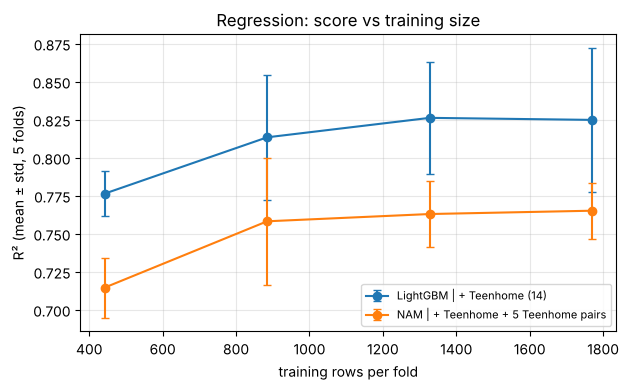

In [11]:
import matplotlib.pyplot as plt
lc = pd.DataFrame(rows)
tab = lc.groupby(["model", "frac"]).agg(n_train=("n_train", "mean"), mean=("r2", "mean"), std=("r2", "std")).reset_index()
wide = lc.pivot_table(index=["frac", "fold"], columns="model", values="r2")
nn_col = [c for c in wide.columns if not c.startswith("LightGBM")][0]; lgb_col = [c for c in wide.columns if c.startswith("LightGBM")][0]
gap = (wide[lgb_col] - wide[nn_col]).groupby(level=0).agg(["mean", "std"])
print(tab.round(4).to_string(index=False)); print("\ngap (LightGBM minus NAM) by training share:"); print(gap.round(4).to_string())
json.dump({"k": K, "fracs": FRACS, "rows": rows, "gap": gap.reset_index().to_dict("records")},
          open("weights_V7_1/regression_pytorch_learning_curve.json", "w"), indent=2)
fig, ax = plt.subplots(figsize=(6.4, 4))
for m, g in tab.groupby("model"):
    ax.errorbar(g["n_train"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=m)
ax.set_xlabel("training rows per fold"); ax.set_ylabel("R² (mean ± std, 5 folds)")
ax.set_title("Regression: score vs training size"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("media/learncurve_reg_V7_1.png", dpi=160); plt.show()